In [ ]:
from pathlib import Path
import sys

for _parent in (Path.cwd(), *Path.cwd().parents):
    if (_parent / "src" / "regression_module.py").exists():
        sys.path.insert(0, str(_parent / "src"))
        break


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, copy
from logistic_module import *

In [2]:
X_train, y_train = load_data('microchip_test_results.csv')

In [3]:
print(f"X_train:\n{X_train[:5]}")
print(f"Type of X_train: {type(X_train)}")

print(f"\ny_train:\n{y_train[:5]}")
print(f"Type of y_train: {type(y_train)}")

X_train:
[[ 0.051267  0.69956 ]
 [-0.092742  0.68494 ]
 [-0.21371   0.69225 ]
 [-0.375     0.50219 ]
 [-0.51325   0.46564 ]]
Type of X_train: <class 'numpy.ndarray'>

y_train:
[1. 1. 1. 1. 1.]
Type of y_train: <class 'numpy.ndarray'>


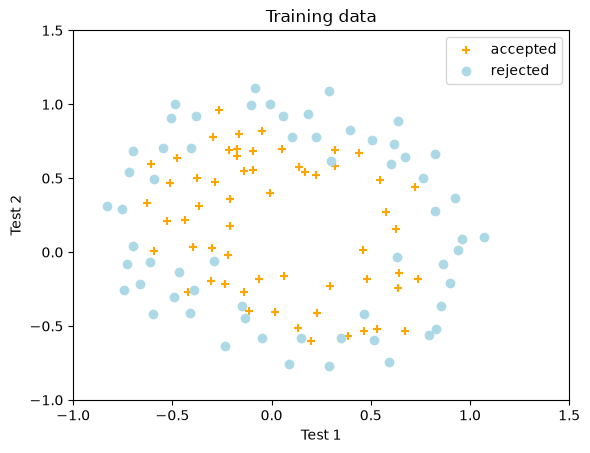

In [4]:
# visualize our data
positive = y_train == 1 # admitted students
negative = y_train == 0 # not admitted students

plt.scatter(X_train[positive, 0], X_train[positive, 1], c='orange', marker='+', label='accepted')
plt.scatter(X_train[negative, 0], X_train[negative, 1], c='lightblue', marker='o', label='rejected')

plt.xlabel("Test 1")
plt.ylabel("Test 2")
plt.title("Training data")
plt.axis([-1,1.5,-1,1.5])
plt.legend()
plt.show()

In [5]:
# feature mapping function -> map features to polynomial features
def map_feature(X1, X2):
    X1 = np.atleast_1d(X1)
    X2 = np.atleast_1d(X2)
    out = []
    degree = 6
    for i in range(1, degree+1):
        for j in range(0, i+1):
            out.append((X1**(i-j) * (X2**j)))
    return np.stack(out, axis=1)

In [6]:
print(f"Original shape of data: {X_train.shape}")

mapped_X = map_feature(X_train[:,0], X_train[:,1])

print(f"Shape after feature mapping: {mapped_X.shape}")

Original shape of data: (118, 2)
Shape after feature mapping: (118, 27)


In [7]:
print(f"X_train[0]: \n{X_train[0]}")
print(f"\nmapped X_train[0]: \n{mapped_X[0]}") # first row

X_train[0]: 
[0.051267 0.69956 ]

mapped X_train[0]: 
[5.12670000e-02 6.99560000e-01 2.62830529e-03 3.58643425e-02
 4.89384194e-01 1.34745327e-04 1.83865725e-03 2.50892595e-02
 3.42353606e-01 6.90798869e-06 9.42624411e-05 1.28625106e-03
 1.75514423e-02 2.39496889e-01 3.54151856e-07 4.83255257e-06
 6.59422333e-05 8.99809795e-04 1.22782870e-02 1.67542444e-01
 1.81563032e-08 2.47750473e-07 3.38066048e-06 4.61305487e-05
 6.29470940e-04 8.58939846e-03 1.17205992e-01]


In [8]:
def sigmoid(z):
    g = 1 / (1 + np.exp(-z))
    return g

In [9]:
def compute_cost_reg(X, y, w, b, lambda_):
    m,n = X.shape
    cost = 0
    for i in range(m):
        z = np.dot(X[i], w) + b
        f_wb = sigmoid(z)
        cost += -y[i] * np.log(f_wb) - (1-y[i]) * np.log(1-f_wb)
    cost /= m
    reg_cost = 0
    for j in range(n):
        reg_cost += w[j]**2
    reg_cost = (lambda_/(2*m)) * reg_cost
    total_cost = cost + reg_cost
    return total_cost

In [10]:
np.random.seed(1)
initial_w = np.random.rand(mapped_X.shape[1]) - 0.5
initial_b = 0.5
lambda_ = 0.5
cost = compute_cost_reg(mapped_X, y_train, initial_w, initial_b, lambda_)

print("Regularized cost :", cost)

Regularized cost : 0.6618252552483948


In [11]:
def compute_gradient_reg(X, y, w, b, lambda_):
    m,n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0
    for i in range(m):
        f_wb = sigmoid(np.dot(X[i], w) + b)
        err = f_wb - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i,j]
        dj_db += err
    dj_dw /= m
    dj_db /= m
    for j in range(n):
        dj_dw[j] += (lambda_/m) * w[j]
    return dj_dw, dj_db

In [12]:
np.random.seed(1) 
initial_w  = np.random.rand(mapped_X.shape[1]) - 0.5 
initial_b = 0.5
 
lambda_ = 0.5
dj_dw, dj_db = compute_gradient_reg(mapped_X, y_train, initial_w, initial_b, lambda_)

print(f"dj_db: {dj_db}", )
print(f"First few elements of regularized dj_dw:\n {dj_dw[:4].tolist()}", )

dj_db: 0.07138288792343662
First few elements of regularized dj_dw:
 [-0.010386028450548701, 0.011409852883280122, 0.0536273463274574, 0.003140278267313462]


In [13]:
def gradient_descent(X, y, w, b, lambda_, alpha, num_iters):
    hist = {}
    hist['cost'] = []
    hist['parameters'] = []
    # hist['gradients'] = []
    for i in range(num_iters):
        dj_dw, dj_db = compute_gradient_reg(X, y, w, b, lambda_)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        if i<100000:
            hist['cost'].append(compute_cost_reg(X, y, w,b ,lambda_))
            hist['parameters'].append((w,b))
            # hist['gradients'].append((dj_dw, dj_db))
        if i % math.ceil(num_iters / 10) == 0:
            print(
                f"Iteration {i:5}: Cost: {hist['cost'][-1]:8.2f}",
            )
    return w, b, hist

In [14]:
np.random.seed(1)
initial_w = np.random.rand(mapped_X.shape[1])-0.5
initial_b = 1.

# Set regularization parameter lambda_ (you can try varying this)
lambda_ = 0.01    

# Some gradient descent settings
iterations = 100000
alpha = 0.01

w,b, hist = gradient_descent(mapped_X, y_train, initial_w, initial_b, lambda_, alpha, iterations)

Iteration     0: Cost:     0.72
Iteration 10000: Cost:     0.45
Iteration 20000: Cost:     0.40
Iteration 30000: Cost:     0.38
Iteration 40000: Cost:     0.37
Iteration 50000: Cost:     0.36
Iteration 60000: Cost:     0.36
Iteration 70000: Cost:     0.35
Iteration 80000: Cost:     0.35
Iteration 90000: Cost:     0.35


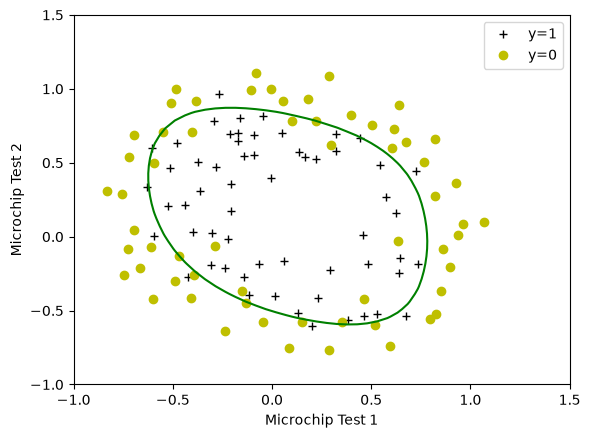

In [15]:
plot_decision_boundary(w, b, mapped_X, y_train)
# Set the y-axis label
plt.ylabel('Microchip Test 2') 
# Set the x-axis label
plt.xlabel('Microchip Test 1') 
plt.legend(loc="upper right")
plt.show()

In [18]:
def predict(X, w, b):
    m = X.shape[0]
    p = np.zeros(m)
    for i in range(m):
        p[i] = sigmoid(np.dot(X[i], w) + b)
        p[i] = 1 if p[i] >= 0.5 else 0
    return p

In [19]:
#Compute accuracy on the training set
p = predict(mapped_X, w, b)

print('Train Accuracy: %f'%(np.mean(p == y_train) * 100))

Train Accuracy: 83.898305
